# Klasifikasi Citra Penyakit Kulit MonkeyPox (MSLD v2.0)
**Studi Komparasi 3 Arsitektur Deep Learning:** `SimpleCNN`, `ModifiedCNN`, dan `MobileNetV3-Small`

---
### Ringkasan Alur Eksperimen
1. **Dataset:** *Mpox Skin Lesion Dataset v2.0 (MSLD v2.0)* yang terdiri dari 6 kelas (`Chickenpox`, `Cowpox`, `HFMD`, `Healthy`, `Measles`, `Monkeypox`).
2. **Skema Pembagian Data (*Zero Data Leakage*):** Menggunakan partisi standar **5-Fold Cross Validation** bawaan dataset. Data latih (*Train*) menggabungkan citra asli (`Original Images`) dan augmentasi (`Augmented Images`), sedangkan data validasi (`Valid`) dan pengujian (`Test`) menggunakan citra asli murni.
3. **EDA:** Distribusi kelas, contoh citra, ukuran citra, efek CLAHE, dan contoh augmentasi.
4. **Pre-processing Citra:** Eksplorasi 3 skema (*tanpa pre-processing*, **CLAHE**, dan **Shades of Gray**). Skema utama: peningkatan kontras lokal menggunakan **CLAHE** (*Contrast Limited Adaptive Histogram Equalization*) pada kanal pencahayaan (*Lightness* / ruang warna LAB), diikuti *resize* `224 × 224` piksel dan normalisasi standar ImageNet.
5. **Model yang Dibandingkan:**
   * **`SimpleCNN`**: Arsitektur CNN dasar 3-blok konvolusi (*baseline from scratch*).
   * **`ModifiedCNN`**: Arsitektur CNN 4-blok konvolusi ganda dengan *Batch Normalization*, aktivasi *SiLU*, blok atensi kanal *Squeeze-and-Excitation (SE)*, dan *Spatial Dropout*.
   * **`MobileNetV3-Small`**: Arsitektur ringan berbasis *Transfer Learning* (*pre-trained* ImageNet).
6. **Metrik Evaluasi:** Rata-rata 5-Fold untuk *Accuracy*, *Macro Precision*, *Macro Recall*, *Macro F1-Score*, *Macro ROC-AUC*, serta *Confusion Matrix*.

---
## Tahap 1: Koneksi Google Drive & Ekstraksi Dataset
Menghubungkan Google Colab ke Google Drive dan mengekstrak arsip `Dataset_Mpox.zip` ke direktori lokal sementara `/content/DATASET_MPOX` agar proses pembacaan gambar berjalan cepat.

In [1]:
from google.colab import drive
import zipfile, os

drive.mount('/content/drive')

zip_path = '/content/drive/MyDrive/Dataset_Mpox.zip'
extract_path = '/content/DATASET_MPOX'

if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

print('Ekstraksi dataset selesai. Isi direktori:', os.listdir(extract_path))

Mounted at /content/drive
Ekstraksi dataset selesai. Isi direktori: ['Augmented Images', 'Original Images', 'Keywords.jpg', 'datalog.xlsx']


---
## Tahap 2: Import Library & Konfigurasi Parameter
Mengimpor seluruh pustaka PyTorch, OpenCV, Scikit-Learn, dan Matplotlib, serta menetapkan hyperparameter eksperimen dalam satu kamus `CONFIG` agar konsisten di seluruh lipatan (*fold*).

> **Revisi:** custom CNN dilatih hingga maksimal 25 epoch (early stopping, patience 5) karena sebelumnya *underfitting*; MobileNet memakai augmentasi kuat dan LR 1e-4 karena sebelumnya *overfitting*; *class weight* ditambahkan untuk menangani ketidakseimbangan kelas.

> **Catatan:** Parameter `'run_mobilenet': True` melatih ketiga model (`SimpleCNN`, `ModifiedCNN`, `MobileNetV3-Small`) dari awal dengan pipeline yang sama (cache CLAHE, 5-Fold). Ubah ke `False` jika hanya ingin melatih dua model custom.

In [2]:
import random
import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import MobileNet_V3_Small_Weights

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

CONFIG = {
    'seed': 42,
    'dataset_root': '/content/DATASET_MPOX',
    'output_dir': '/content/outputs',
    'checkpoint_dir': '/content/checkpoints',
    'img_size': 224,
    'batch_size': 64,
    'num_folds': 5,
    # [UBAH] Custom CNN masih underfitting di epoch 15 (TrAcc ~0.65-0.70, loss masih turun),
    #        jadi diberi epoch lebih banyak (maksimal 25). MobileNet sudah konvergen cepat, cukup 15.
    'epochs_custom': 25,
    'epochs_pretrained': 15,
    # [UBAH] Early stopping: berhenti kalau Val F1 tidak membaik selama N epoch berturut-turut
    'patience': 5,
    'lr_custom': 1e-3,          # tetap, custom CNN butuh belajar lebih cepat, bukan lebih lambat
    'lr_pretrained': 1e-4,      # [UBAH] 3e-4 -> 1e-4: MobileNet overfit (TrAcc 0.99 di epoch 5)
    # [UBAH] Class weight untuk mengatasi dominasi kelas Monkeypox
    'use_class_weights': True,
    'weight_decay': 1e-2,
    'use_clahe': True,
    'num_workers': 2,
    'run_mobilenet': True,
    # [UBAH] Eksplorasi pre-processing (Ketentuan Tugas No. 2):
    #        model di bawah dilatih ulang dengan 3 skema pre-processing untuk dibandingkan
    'run_preproc_ablation': True,
    'ablation_model': 'MobileNetV3-Small',
    'device': 'cuda' if torch.cuda.is_available() else 'cpu'
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)
os.makedirs(CONFIG['checkpoint_dir'], exist_ok=True)

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(CONFIG['seed'])
print(f"Setup berhasil | Device aktif: {CONFIG['device']} | CLAHE: {CONFIG['use_clahe']}")

Setup berhasil | Device aktif: cuda | CLAHE: True


---
## Tahap 3: Pre-processing Citra (CLAHE) & Dataset Loader
* **`ApplyCLAHE`**: Mengonversi citra RGB ke ruang warna CIELAB (`LAB`) dan menerapkan *Contrast Limited Adaptive Histogram Equalization* hanya pada kanal pencahayaan (`L`) agar detail tekstur lesi lebih tajam tanpa mengubah warna kulit asli.
* **`ShadesOfGray`**: Metode *color constancy* yang menormalkan pencahayaan/warna citra (estimasi iluminan dengan norma Minkowski p=6) sehingga variasi warna akibat kamera dan kondisi cahaya berkurang. Digunakan sebagai pembanding CLAHE pada eksplorasi pre-processing.
* **`find_fold_dirs` & `load_images_from_dirs`**: Memetakan direktori `Train` (gabungan *Original + Augmented*), `Valid` (*Original*), dan `Test` (*Original*) secara otomatis pada masing-masing fold tanpa kebocoran data.

In [3]:
class ApplyCLAHE:
    def __init__(self, clip_limit=2.0, tile_grid_size=(8, 8)):
        self.clip_limit = clip_limit
        self.tile_grid_size = tile_grid_size

    def __call__(self, img):
        lab = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        l_clahe = cv2.createCLAHE(clipLimit=self.clip_limit, tileGridSize=self.tile_grid_size).apply(l)
        return Image.fromarray(cv2.cvtColor(cv2.merge((l_clahe, a, b)), cv2.COLOR_LAB2RGB))

class ShadesOfGray:
    """[BARU] Color constancy Shades of Gray (Finlayson & Trezzi, 2004).
    Mengestimasi warna cahaya dengan norma Minkowski orde p, lalu
    menormalkan tiap kanal supaya citra tampak seperti di bawah cahaya netral."""
    def __init__(self, power=6):
        self.power = power

    def __call__(self, img):
        arr = np.asarray(img).astype(np.float32)
        illum = np.power(np.mean(np.power(arr, self.power), axis=(0, 1)), 1.0 / self.power)
        illum = illum / (np.sqrt(np.sum(illum ** 2)) + 1e-6)
        arr = arr / (illum * np.sqrt(3) + 1e-6)
        return Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))

def get_transforms(img_size, use_clahe=True, strong_aug=False):
    pre = [ApplyCLAHE()] if use_clahe else []
    norm = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    if strong_aug:
        # [UBAH] Augmentasi kuat untuk model yang overfit (MobileNet).
        # Variasi posisi, rotasi, dan warna ringan supaya model tidak menghafal citra latih.
        aug = [
            transforms.RandomResizedCrop(img_size, scale=(0.75, 1.0)),
            transforms.RandomHorizontalFlip(0.5),
            transforms.RandomVerticalFlip(0.2),
            transforms.RandomRotation(20),
            transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.15, hue=0.02),
        ]
    else:
        # [UBAH] Augmentasi ringan untuk custom CNN yang underfit,
        # augmentasi berat justru membuat tugasnya makin sulit.
        aug = [
            transforms.Resize((img_size, img_size)),
            transforms.RandomHorizontalFlip(0.5),
        ]
    train_tf = transforms.Compose(pre + aug + [
        transforms.ToTensor(),
        norm
    ])
    eval_tf = transforms.Compose(pre + [
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        norm
    ])
    return train_tf, eval_tf

def find_fold_dirs(root_dir, fold_num):
    orig_train = aug_train = orig_valid = orig_test = None
    fold_tag = f'fold{fold_num}'
    for dirpath, _, _ in os.walk(root_dir):
        norm_path = dirpath.replace('\\', '/').lower()
        base_name = os.path.basename(dirpath).lower()
        if fold_tag in norm_path:
            is_aug = 'aug' in norm_path
            if base_name == 'train':
                if is_aug:
                    aug_train = dirpath
                else:
                    orig_train = dirpath
            elif base_name == 'valid' and not is_aug:
                orig_valid = dirpath
            elif base_name == 'test' and not is_aug:
                orig_test = dirpath
    if not all([orig_train, aug_train, orig_valid, orig_test]):
        raise FileNotFoundError(f'Struktur folder {fold_tag} tidak lengkap di {root_dir}')
    return orig_train, aug_train, orig_valid, orig_test

def load_images_from_dirs(dir_list, class_to_idx):
    filepaths, labels = [], []
    valid_ext = ('.jpg', '.jpeg', '.png', '.bmp')
    for d in dir_list:
        for cls_name, idx in class_to_idx.items():
            cls_dir = os.path.join(d, cls_name)
            for fname in sorted(os.listdir(cls_dir)):
                if fname.lower().endswith(valid_ext):
                    filepaths.append(os.path.join(cls_dir, fname))
                    labels.append(idx)
    return np.array(filepaths), np.array(labels)

class SkinLesionDataset(Dataset):
    def __init__(self, filepaths, labels, transform=None):
        self.filepaths = filepaths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.filepaths)

    def __getitem__(self, idx):
        img = Image.open(self.filepaths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, int(self.labels[idx])

orig_tr_1, _, _, _ = find_fold_dirs(CONFIG['dataset_root'], 1)
TARGET_CLASSES = sorted([d for d in os.listdir(orig_tr_1) if os.path.isdir(os.path.join(orig_tr_1, d))])
CLASS_TO_IDX = {c: i for i, c in enumerate(TARGET_CLASSES)}
print(f'Dataset terverifikasi ({len(TARGET_CLASSES)} kelas): {TARGET_CLASSES}')

Dataset terverifikasi (6 kelas): ['Chickenpox', 'Cowpox', 'HFMD', 'Healthy', 'Measles', 'Monkeypox']


---
## Tahap 3B: Exploratory Data Analysis (EDA)
EDA dilakukan **sebelum** cache CLAHE dibuat, supaya citra yang dianalisis masih citra asli. Tujuannya untuk menjustifikasi keputusan pada tahap berikutnya:
1. **Distribusi kelas per split & fold**: dasar penggunaan *class-weighted loss*.
2. **Contoh citra tiap kelas**: melihat kemiripan visual antar kelas.
3. **Ukuran asli citra**: dasar *resize* ke `224 × 224`.
4. **Perbandingan sebelum vs sesudah CLAHE**: bukti visual efek *pre-processing*.
5. **Contoh hasil augmentasi**: memastikan augmentasi tetap realistis.

### EDA 1: Distribusi Jumlah Citra per Kelas

Distribusi citra per kelas - Fold 1


Split,Train (Original),Train (Augmented),Valid,Test
Kelas,,,,
Chickenpox,50,700,16,9
Cowpox,49,686,10,7
HFMD,116,1624,29,16
Healthy,83,1162,22,9
Measles,37,518,12,6
Monkeypox,202,2828,55,27
TOTAL,537,7518,144,74


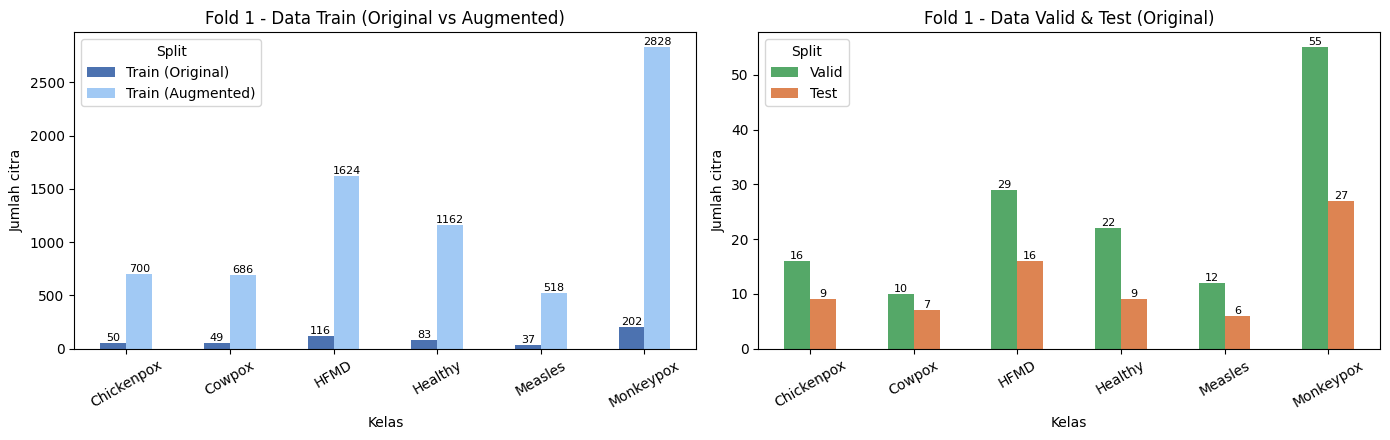

Proporsi kelas pada citra original (%):
Kelas
Chickenpox     9.9
Cowpox         8.7
HFMD          21.3
Healthy       15.1
Measles        7.3
Monkeypox     37.6

Rasio kelas terbanyak : tersedikit = 5.16 : 1

Jumlah citra Test per fold:
Fold
1    74
2    82
3    64
4    81
5    63


In [4]:
# Hitung jumlah citra per kelas untuk setiap fold dan split
rows = []
for fold in range(1, CONFIG['num_folds'] + 1):
    orig_tr, aug_tr, orig_val, orig_ts = find_fold_dirs(CONFIG['dataset_root'], fold)
    split_dirs = {
        'Train (Original)': [orig_tr],
        'Train (Augmented)': [aug_tr],
        'Valid': [orig_val],
        'Test': [orig_ts],
    }
    for split_name, dirs in split_dirs.items():
        _, labels = load_images_from_dirs(dirs, CLASS_TO_IDX)
        counts = np.bincount(labels, minlength=len(TARGET_CLASSES))
        for cls, n in zip(TARGET_CLASSES, counts):
            rows.append({'Fold': fold, 'Split': split_name, 'Kelas': cls, 'Jumlah': n})

df_dist = pd.DataFrame(rows)

# Tabel ringkas untuk Fold 1
tabel_f1 = df_dist[df_dist['Fold'] == 1].pivot(index='Kelas', columns='Split', values='Jumlah')
tabel_f1 = tabel_f1[['Train (Original)', 'Train (Augmented)', 'Valid', 'Test']]
tabel_f1.loc['TOTAL'] = tabel_f1.sum()
print('Distribusi citra per kelas - Fold 1')
display(tabel_f1)

# Grafik distribusi Fold 1
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
tabel_f1.drop('TOTAL')[['Train (Original)', 'Train (Augmented)']].plot(kind='bar', ax=axes[0], color=['#4C72B0', '#A1C9F4'])
axes[0].set_title('Fold 1 - Data Train (Original vs Augmented)')
axes[0].set_ylabel('Jumlah citra'); axes[0].tick_params(axis='x', rotation=30)
for c in axes[0].containers:
    axes[0].bar_label(c, fontsize=8)

tabel_f1.drop('TOTAL')[['Valid', 'Test']].plot(kind='bar', ax=axes[1], color=['#55A868', '#DD8452'])
axes[1].set_title('Fold 1 - Data Valid & Test (Original)')
axes[1].set_ylabel('Jumlah citra'); axes[1].tick_params(axis='x', rotation=30)
for c in axes[1].containers:
    axes[1].bar_label(c, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG['output_dir'], 'eda_distribusi_kelas_fold1.png'), dpi=300)
plt.show()

# Proporsi kelas pada data original (Train + Valid + Test fold 1 = seluruh citra original)
orig_total = tabel_f1.drop('TOTAL')[['Train (Original)', 'Valid', 'Test']].sum(axis=1)
proporsi = (orig_total / orig_total.sum() * 100).round(1)
print('Proporsi kelas pada citra original (%):')
print(proporsi.to_string())
print(f'\nRasio kelas terbanyak : tersedikit = {orig_total.max() / orig_total.min():.2f} : 1')

# Cek konsistensi jumlah Test antar fold
print('\nJumlah citra Test per fold:')
print(df_dist[df_dist['Split'] == 'Test'].groupby('Fold')['Jumlah'].sum().to_string())

### EDA 2: Contoh Citra Tiap Kelas

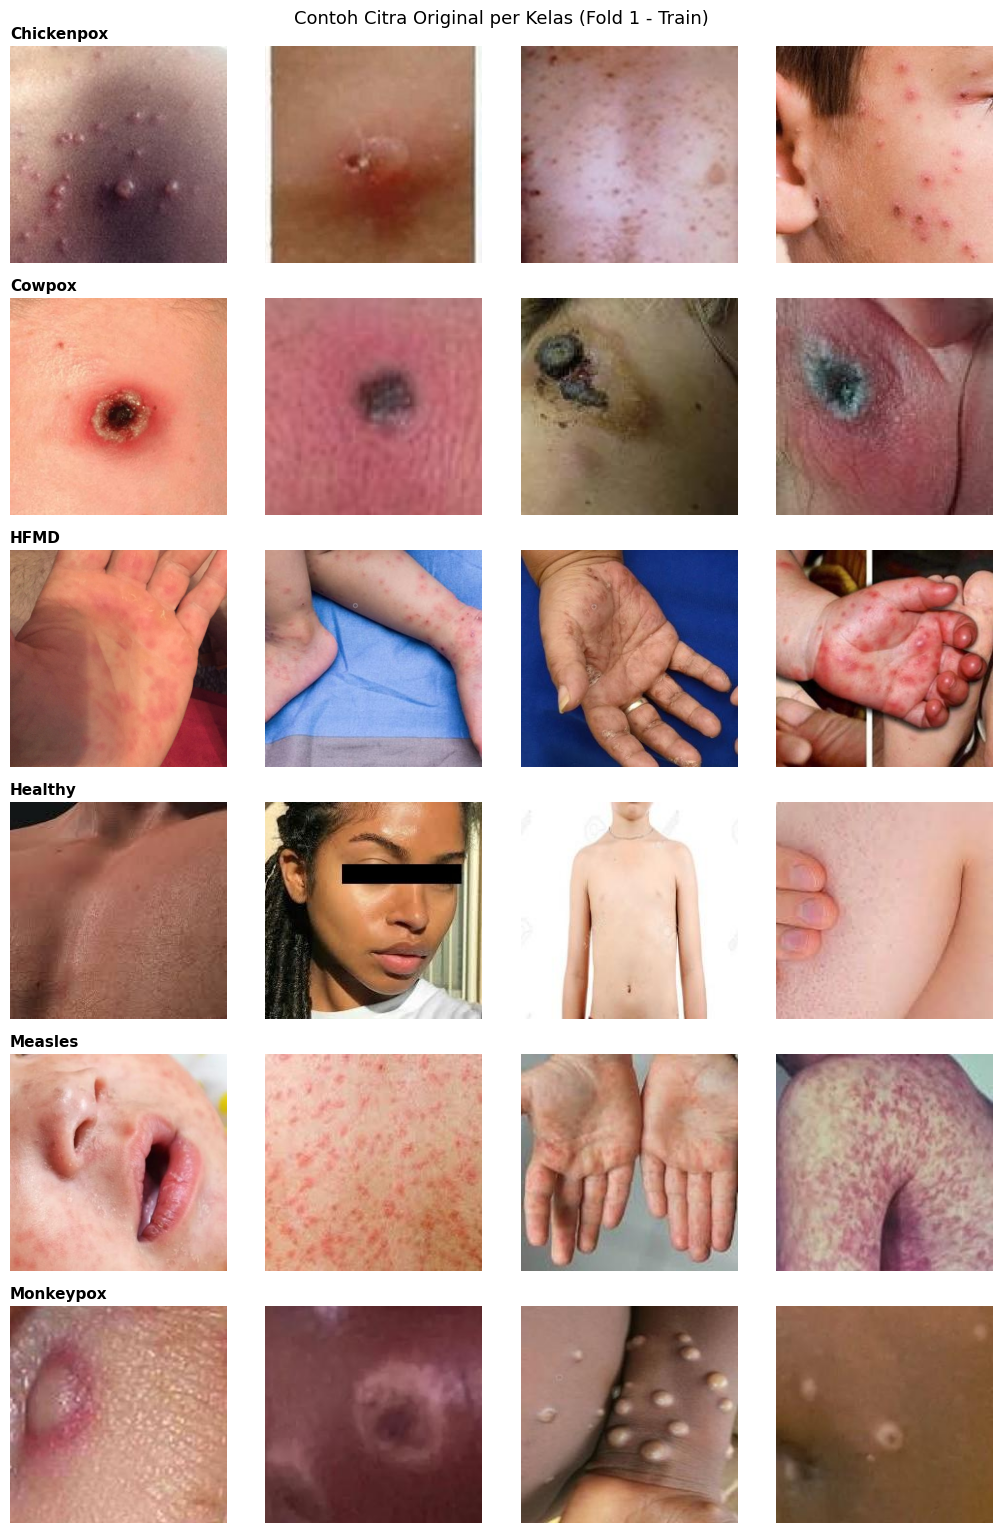

In [5]:
n_samples = 4
orig_tr_1, _, _, _ = find_fold_dirs(CONFIG['dataset_root'], 1)
rng = np.random.default_rng(CONFIG['seed'])

fig, axes = plt.subplots(len(TARGET_CLASSES), n_samples, figsize=(n_samples * 2.6, len(TARGET_CLASSES) * 2.6))
for r, cls in enumerate(TARGET_CLASSES):
    cls_dir = os.path.join(orig_tr_1, cls)
    files = sorted(f for f in os.listdir(cls_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')))
    picks = rng.choice(files, size=min(n_samples, len(files)), replace=False)
    for c in range(n_samples):
        ax = axes[r, c]
        ax.axis('off')
        if c < len(picks):
            ax.imshow(Image.open(os.path.join(cls_dir, picks[c])).convert('RGB'))
        if c == 0:
            ax.set_title(cls, loc='left', fontsize=11, fontweight='bold')
plt.suptitle('Contoh Citra Original per Kelas (Fold 1 - Train)', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG['output_dir'], 'eda_contoh_citra.png'), dpi=200)
plt.show()

### EDA 3: Ukuran Asli Citra

Total citra original: 755

Statistik ukuran (piksel):


,Lebar,Tinggi
count,755.0,755.0
mean,270.3,270.1
std,173.6,173.6
min,69.0,69.0
25%,224.0,224.0
50%,224.0,224.0
75%,225.0,225.0
max,2448.0,2448.0


5 resolusi paling sering:
Lebar  Tinggi
224    224       446
300    300        19
183    183        15
225    225        12
194    194         6


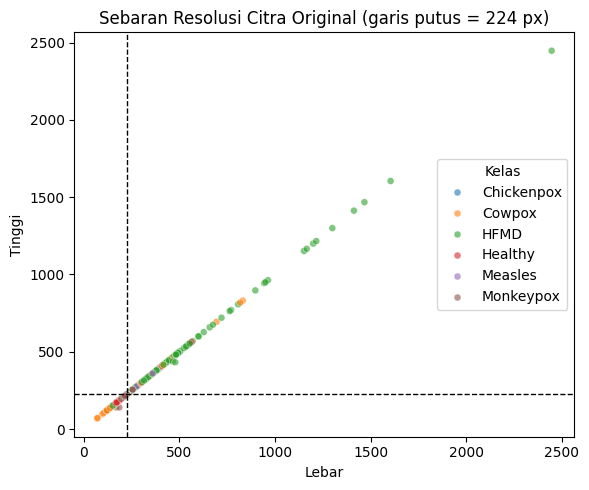

In [6]:
# Ambil semua citra original (Train + Valid + Test pada Fold 1 = seluruh citra original)
orig_tr_1, _, orig_val_1, orig_ts_1 = find_fold_dirs(CONFIG['dataset_root'], 1)
paths_all, labels_all = load_images_from_dirs([orig_tr_1, orig_val_1, orig_ts_1], CLASS_TO_IDX)

sizes = [Image.open(p).size for p in paths_all]   # .size hanya membaca header, cepat
df_size = pd.DataFrame(sizes, columns=['Lebar', 'Tinggi'])
df_size['Kelas'] = [TARGET_CLASSES[i] for i in labels_all]

print(f'Total citra original: {len(df_size)}')
print('\nStatistik ukuran (piksel):')
display(df_size[['Lebar', 'Tinggi']].describe().round(1))
print('5 resolusi paling sering:')
print(df_size.groupby(['Lebar', 'Tinggi']).size().sort_values(ascending=False).head().to_string())

plt.figure(figsize=(6, 5))
sns.scatterplot(data=df_size, x='Lebar', y='Tinggi', hue='Kelas', alpha=0.6, s=25)
plt.axvline(224, color='k', ls='--', lw=1); plt.axhline(224, color='k', ls='--', lw=1)
plt.title('Sebaran Resolusi Citra Original (garis putus = 224 px)')
plt.tight_layout()
plt.savefig(os.path.join(CONFIG['output_dir'], 'eda_ukuran_citra.png'), dpi=200)
plt.show()

### EDA 4: Perbandingan Skema Pre-processing (Asli vs CLAHE vs Shades of Gray)

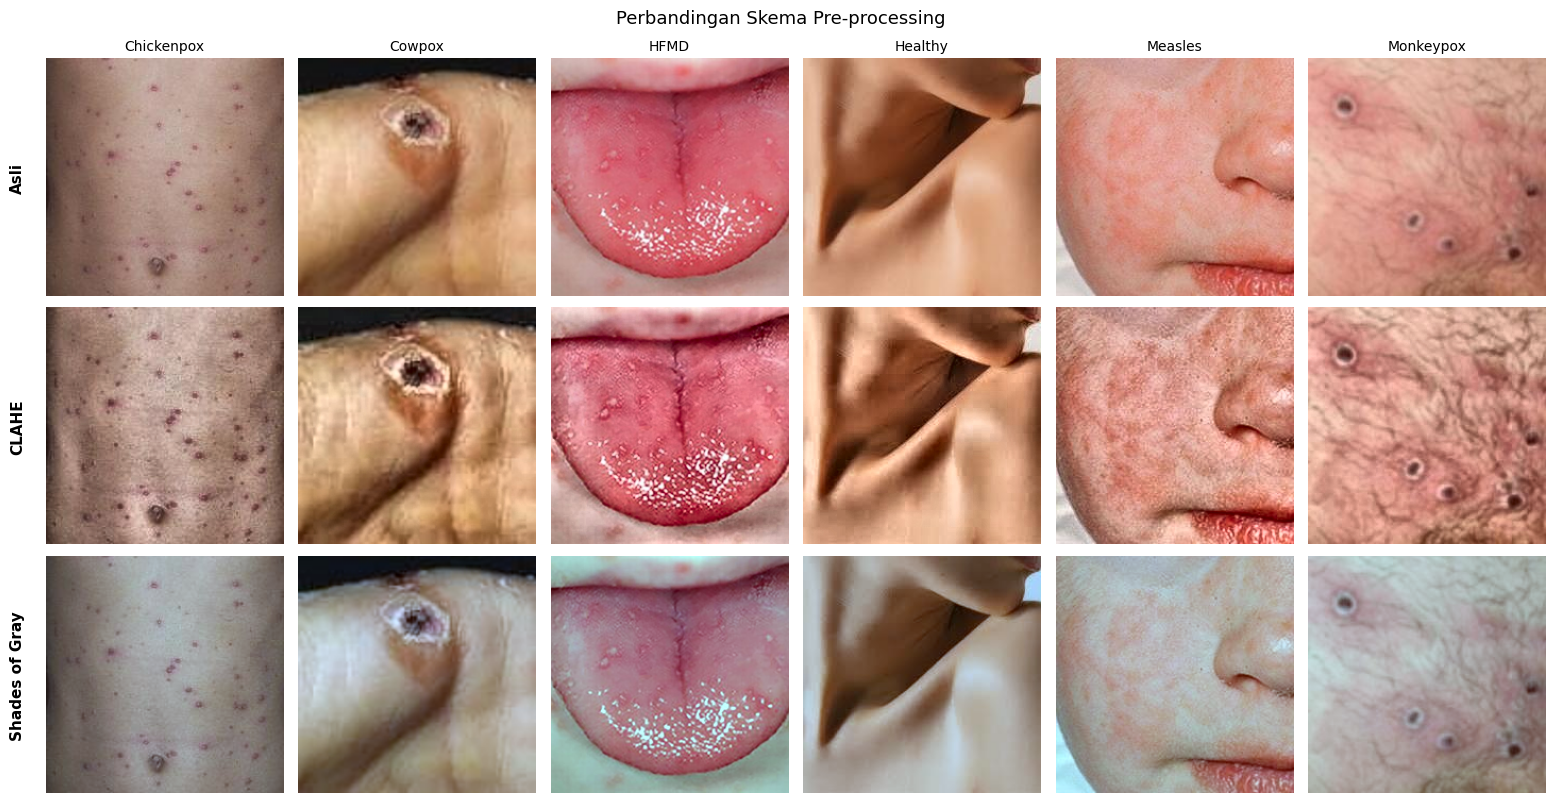

In [7]:
clahe_demo, sog_demo = ApplyCLAHE(), ShadesOfGray()
row_names = ['Asli', 'CLAHE', 'Shades of Gray']
fig, axes = plt.subplots(3, len(TARGET_CLASSES), figsize=(len(TARGET_CLASSES) * 2.6, 8.2))
for c, cls in enumerate(TARGET_CLASSES):
    p = paths_all[labels_all == CLASS_TO_IDX[cls]][0]   # ambil 1 citra per kelas
    img = Image.open(p).convert('RGB').resize((224, 224))
    for r, shown in enumerate([img, clahe_demo(img), sog_demo(img)]):
        axes[r, c].imshow(shown)
        axes[r, c].axis('off')
    axes[0, c].set_title(cls, fontsize=10)
for r, name in enumerate(row_names):
    axes[r, 0].text(-20, 112, name, rotation=90, va='center', ha='right', fontsize=11, fontweight='bold')
plt.suptitle('Perbandingan Skema Pre-processing', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG['output_dir'], 'eda_preprocessing_comparison.png'), dpi=200)
plt.show()

### EDA 5: Contoh Hasil Augmentasi Kuat (dipakai MobileNetV3)

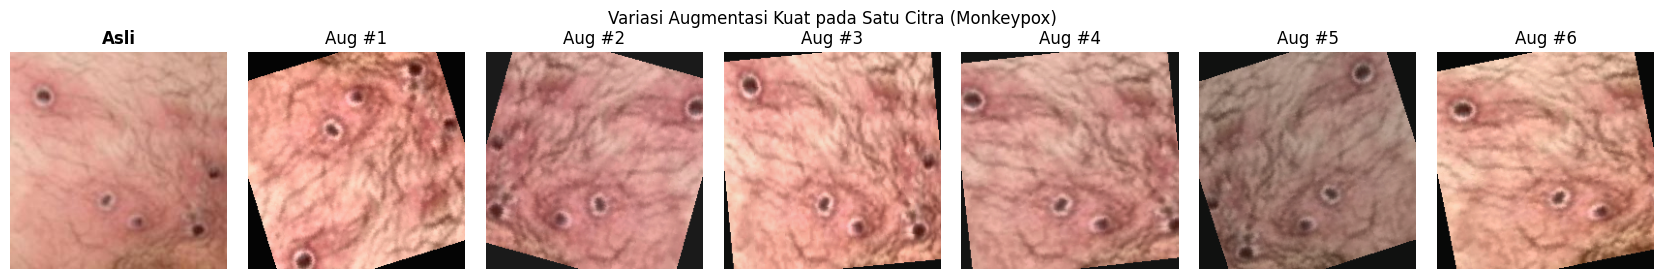

In [8]:
# Fungsi untuk mengembalikan tensor ternormalisasi ke citra yang bisa ditampilkan
MEAN = np.array([0.485, 0.456, 0.406]); STD = np.array([0.229, 0.224, 0.225])
def denorm(t):
    return np.clip(t.permute(1, 2, 0).numpy() * STD + MEAN, 0, 1)

strong_tf, _ = get_transforms(CONFIG['img_size'], use_clahe=True, strong_aug=True)
demo_img = Image.open(paths_all[labels_all == CLASS_TO_IDX['Monkeypox']][0]).convert('RGB')

n_aug = 6
fig, axes = plt.subplots(1, n_aug + 1, figsize=((n_aug + 1) * 2.4, 2.8))
axes[0].imshow(demo_img.resize((224, 224))); axes[0].set_title('Asli', fontweight='bold')
for i in range(1, n_aug + 1):
    axes[i].imshow(denorm(strong_tf(demo_img))); axes[i].set_title(f'Aug #{i}')
for ax in axes:
    ax.axis('off')
plt.suptitle('Variasi Augmentasi Kuat pada Satu Citra (Monkeypox)', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG['output_dir'], 'eda_contoh_augmentasi.png'), dpi=200)
plt.show()

---
## Tahap 3A: Cache Pre-processing (Optimasi Kecepatan Training)
Setiap skema pre-processing diterapkan bersama *resize* `224 × 224` piksel **satu kali di awal** ke direktori cache masing-masing secara paralel (`ThreadPoolExecutor`):

| Skema | Direktori cache |
|---|---|
| Tanpa pre-processing (hanya resize) | `/content/DATASET_MPOX_NONE` |
| CLAHE (skema utama) | `/content/DATASET_MPOX_CLAHE` |
| Shades of Gray | `/content/DATASET_MPOX_SOG` |

Cache `NONE` dan `SOG` hanya dibuat jika `'run_preproc_ablation': True`. Setelah cache terbentuk, `'use_clahe'` disetel ke `False` agar CPU tidak mengulang proses OpenCV di setiap *epoch*.

In [9]:
import shutil
from concurrent.futures import ThreadPoolExecutor

CONFIG['raw_root'] = '/content/DATASET_MPOX'   # path dataset asli (hasil ekstraksi zip)
PREPROC_FNS = {'none': None, 'clahe': ApplyCLAHE(), 'sog': ShadesOfGray()}
PREPROC_LABELS = {'none': 'Tanpa Pre-processing', 'clahe': 'CLAHE', 'sog': 'Shades of Gray'}

def build_preproc_cache(method):
    cache_root = f'/content/DATASET_MPOX_{method.upper()}'
    done_flag = os.path.join(cache_root, '_DONE')   # penanda cache sudah lengkap
    if os.path.exists(done_flag):
        return cache_root
    fn = PREPROC_FNS[method]
    tasks = []
    for root, _, files in os.walk(CONFIG['raw_root']):
        rel = os.path.relpath(root, CONFIG['raw_root'])
        dst_dir = os.path.join(cache_root, rel)
        os.makedirs(dst_dir, exist_ok=True)
        for f in files:
            src_f = os.path.join(root, f)
            dst_f = os.path.join(dst_dir, f)
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
                tasks.append((src_f, dst_f))
            else:
                shutil.copy2(src_f, dst_f)

    def process_img(pair):
        img = Image.open(pair[0]).convert('RGB').resize((CONFIG['img_size'], CONFIG['img_size']))
        if fn is not None:
            img = fn(img)
        img.save(pair[1], quality=95)

    with ThreadPoolExecutor(max_workers=4) as ex:
        list(ex.map(process_img, tasks))
    open(done_flag, 'w').close()
    return cache_root

methods = ['none', 'clahe', 'sog'] if CONFIG['run_preproc_ablation'] else ['clahe']
PREPROC_ROOTS = {}
for m in methods:
    PREPROC_ROOTS[m] = build_preproc_cache(m)
    print(f'Cache {PREPROC_LABELS[m]:22s} -> {PREPROC_ROOTS[m]}')

CONFIG['dataset_root'] = PREPROC_ROOTS['clahe']   # skema utama untuk 3 model
CONFIG['use_clahe'] = False  # Sudah diterapkan di cache, tidak perlu diulang tiap epoch
print('Semua cache pre-processing 224x224 siap!')

Cache Tanpa Pre-processing   -> /content/DATASET_MPOX_NONE
Cache CLAHE                  -> /content/DATASET_MPOX_CLAHE
Cache Shades of Gray         -> /content/DATASET_MPOX_SOG
Semua cache pre-processing 224x224 siap!


---
## Tahap 4: Definisi 3 Arsitektur Model Deep Learning
1. **`SimpleCNN`**: 3 lapisan konvolusi (`32 → 64 → 128` filter) dengan aktivasi *ReLU*, *MaxPooling*, dan *Global Average Pooling*.
2. **`ModifiedCNN`**: 4 blok konvolusi ganda (`32 → 64 → 128 → 256` filter) dengan *BatchNorm2d*, aktivasi *SiLU*, modul perhatian *Squeeze-and-Excitation (`SEBlock`)* untuk membobotkan fitur kanal penting, serta *Dropout2d*.
3. **`MobileNetV3-Small`**: Model *pre-trained* ImageNet dengan modifikasi lapisan klasifikasi akhir (`Dropout(0.3)` + `Linear`).

In [10]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64), nn.ReLU(inplace=True),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

class SEBlock(nn.Module):
    def __init__(self, ch, r=8):
        super().__init__()
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(ch, ch // r), nn.SiLU(inplace=True),
            nn.Linear(ch // r, ch), nn.Sigmoid()
        )

    def forward(self, x):
        return x * self.fc(x).unsqueeze(-1).unsqueeze(-1)

class ModifiedCNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.SiLU(inplace=True),
            nn.Conv2d(32, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.SiLU(inplace=True),
            nn.MaxPool2d(2), nn.Dropout2d(0.05)  # [UBAH] 0.1 -> 0.05
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.SiLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.SiLU(inplace=True),
            SEBlock(64), nn.MaxPool2d(2), nn.Dropout2d(0.1)  # [UBAH] 0.15 -> 0.1
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1, bias=False), nn.BatchNorm2d(128), nn.SiLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1, bias=False), nn.BatchNorm2d(128), nn.SiLU(inplace=True),
            SEBlock(128), nn.MaxPool2d(2), nn.Dropout2d(0.1)  # [UBAH] 0.2 -> 0.1
        )
        self.block4 = nn.Sequential(
            nn.Conv2d(128, 256, 3, padding=1, bias=False), nn.BatchNorm2d(256), nn.SiLU(inplace=True),
            SEBlock(256), nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            # [UBAH] Regularisasi dikurangi karena model underfitting
            nn.Dropout(0.2),   # 0.35 -> 0.2
            nn.Linear(256, 128), nn.SiLU(inplace=True),
            nn.Dropout(0.1),   # 0.25 -> 0.1
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        return self.classifier(x)

def build_model(model_name, num_classes, device):
    if model_name == 'SimpleCNN':
        return SimpleCNN(num_classes).to(device)
    elif model_name == 'ModifiedCNN':
        return ModifiedCNN(num_classes).to(device)
    elif model_name == 'MobileNetV3-Small':
        m = models.mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.DEFAULT)
        in_f = m.classifier[3].in_features
        m.classifier[3] = nn.Sequential(nn.Dropout(0.3), nn.Linear(in_f, num_classes))
        return m.to(device)
    raise ValueError(f'Model tidak dikenal: {model_name}')

for name in ['SimpleCNN', 'ModifiedCNN', 'MobileNetV3-Small']:
    m = build_model(name, 6, 'cpu')
    params = sum(p.numel() for p in m.parameters())
    print(f'{name:18s} | Total Parameters: {params:,}')

SimpleCNN          | Total Parameters: 101,894
ModifiedCNN        | Total Parameters: 638,558
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 187MB/s]

MobileNetV3-Small  | Total Parameters: 1,524,006


---
## Tahap 5: Fungsi Training & Evaluasi 5-Fold Cross Validation (Versi Efisien)
Logika eksperimen (5-Fold, class weight, label smoothing, early stopping, pemilihan bobot berdasarkan Val F1) **tidak berubah**. Yang diubah hanya cara komputasinya:
* Gambar 224×224 dibaca **sekali** lalu disimpan sebagai `.npz`, dan seluruh data fold ditaruh di **VRAM GPU** (tanpa `DataLoader`).
* Augmentasi dilakukan di **GPU** per batch (flip, rotasi, crop-zoom, brightness/contrast/saturation), bukan di CPU.
* **Mixed precision (AMP)** dan `channels_last` untuk mempercepat konvolusi di T4.
* Akumulasi loss/akurasi di GPU (tanpa sinkronisasi per batch), ROC-AUC/precision/recall hanya dihitung di evaluasi akhir.

> Catatan: augmentasi kuat di GPU tidak menyertakan *hue jitter* dan memakai *grid_sample* sebagai pengganti `RandomResizedCrop`/`RandomRotation`, sehingga hasil bisa sedikit berbeda dari versi lama.

In [11]:
import math
import torch.nn.functional as F
from concurrent.futures import ThreadPoolExecutor

torch.backends.cudnn.benchmark = True
DEV = CONFIG['device']
USE_AMP = CONFIG.get('use_amp', True) and DEV == 'cuda'
MEAN_T = torch.tensor([0.485, 0.456, 0.406], device=DEV).view(1, 3, 1, 1)
STD_T = torch.tensor([0.229, 0.224, 0.225], device=DEV).view(1, 3, 1, 1)
os.makedirs('/content/npy', exist_ok=True)

def load_split(root, fold, name, dirs):
    f = f"/content/npy/{os.path.basename(root)}_f{fold}_{name}.npz"
    if os.path.exists(f):
        d = np.load(f)
        return d['x'], d['y']
    paths, y = load_images_from_dirs(dirs, CLASS_TO_IDX)
    S = CONFIG['img_size']
    rd = lambda p: np.asarray(Image.open(p).convert('RGB').resize((S, S)))
    with ThreadPoolExecutor(4) as ex:
        x = np.stack(list(ex.map(rd, paths)))
    np.savez(f, x=x, y=y)
    return x, y

def to_gpu(x):
    return torch.from_numpy(x).permute(0, 3, 1, 2).contiguous().to(DEV)

def gpu_aug(x, strong):
    B = x.size(0)
    flip = torch.rand(B, device=x.device) < 0.5
    x = torch.where(flip.view(-1, 1, 1, 1), x.flip(3), x)
    if not strong:
        return x
    vflip = torch.rand(B, device=x.device) < 0.2
    x = torch.where(vflip.view(-1, 1, 1, 1), x.flip(2), x)
    ang = (torch.rand(B, device=x.device) * 2 - 1) * 20 * math.pi / 180
    s = torch.empty(B, device=x.device).uniform_(0.75, 1.0).sqrt()
    tx = (torch.rand(B, device=x.device) * 2 - 1) * (1 - s)
    ty = (torch.rand(B, device=x.device) * 2 - 1) * (1 - s)
    theta = torch.stack([torch.stack([s * ang.cos(), -s * ang.sin(), tx], 1),
                         torch.stack([s * ang.sin(), s * ang.cos(), ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, padding_mode='reflection', align_corners=False)
    r = lambda a: 1 + (torch.rand(B, 1, 1, 1, device=x.device) * 2 - 1) * a
    x = x * r(0.2)
    m = x.mean((1, 2, 3), keepdim=True)
    x = (x - m) * r(0.2) + m
    g = x.mean(1, keepdim=True)
    x = (x - g) * r(0.15) + g
    return x.clamp(0, 1)

def train_one_epoch(model, X, y, criterion, optimizer, scaler, strong):
    model.train()
    n = X.size(0)
    perm = torch.randperm(n, device=DEV)
    loss_sum = torch.zeros((), device=DEV)
    correct = torch.zeros((), device=DEV)
    bs = CONFIG['batch_size']
    for i in range(0, n, bs):
        idx = perm[i:i + bs]
        xb = gpu_aug(X[idx].float().div_(255), strong)
        xb = ((xb - MEAN_T) / STD_T).contiguous(memory_format=torch.channels_last)
        yb = y[idx]
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
            out = model(xb)
            loss = criterion(out, yb)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        loss_sum += loss.detach() * len(idx)
        correct += (out.argmax(1) == yb).sum()
    return loss_sum.item() / n, correct.item() / n

@torch.no_grad()
def evaluate(model, X, y, criterion, full=False):
    model.eval()
    loss_sum = torch.zeros((), device=DEV)
    probs = []
    for i in range(0, X.size(0), 256):
        xb = ((X[i:i + 256].float().div_(255) - MEAN_T) / STD_T).contiguous(memory_format=torch.channels_last)
        with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
            out = model(xb).float()
        loss_sum += criterion(out, y[i:i + 256]) * len(xb)
        probs.append(torch.softmax(out, 1))
    y_true = y.cpu().numpy()
    y_prob = torch.cat(probs).cpu().numpy()
    y_pred = y_prob.argmax(1)
    res = {'loss': loss_sum.item() / len(y_true), 'accuracy': accuracy_score(y_true, y_pred),
           'f1_score': f1_score(y_true, y_pred, average='macro', zero_division=0),
           'y_true': y_true, 'y_pred': y_pred, 'y_prob': y_prob}
    if full:
        res['precision'] = precision_score(y_true, y_pred, average='macro', zero_division=0)
        res['recall'] = recall_score(y_true, y_pred, average='macro', zero_division=0)
        res['roc_auc'] = roc_auc_score(y_true, y_prob, multi_class='ovr', average='macro')
    return res

def run_5fold_experiment(model_name, dataset_root=None, tag='main'):
    dataset_root = dataset_root or CONFIG['dataset_root']
    seed_everything(CONFIG['seed'])
    is_pretrained = (model_name == 'MobileNetV3-Small')
    epochs = CONFIG['epochs_pretrained'] if is_pretrained else CONFIG['epochs_custom']
    lr = CONFIG['lr_pretrained'] if is_pretrained else CONFIG['lr_custom']

    val_rows, test_rows, histories = [], [], []
    all_y_true, all_y_pred, all_y_prob = [], [], []

    for fold in range(1, CONFIG['num_folds'] + 1):
        print(f'\n{"="*45}\n[{model_name} | {tag}] FOLD {fold}/{CONFIG["num_folds"]}\n{"="*45}')
        orig_tr, aug_tr, orig_val, orig_ts = find_fold_dirs(dataset_root, fold)
        X_tr, y_tr = load_split(dataset_root, fold, 'train', [orig_tr, aug_tr])
        X_va, y_va = load_split(dataset_root, fold, 'valid', [orig_val])
        X_ts, y_ts = load_split(dataset_root, fold, 'test', [orig_ts])
        Xtr_g, ytr_g = to_gpu(X_tr), torch.from_numpy(y_tr).to(DEV)
        Xva_g, yva_g = to_gpu(X_va), torch.from_numpy(y_va).to(DEV)
        Xts_g, yts_g = to_gpu(X_ts), torch.from_numpy(y_ts).to(DEV)

        if CONFIG['use_class_weights']:
            counts = np.bincount(y_tr, minlength=len(TARGET_CLASSES))
            w = len(y_tr) / (len(TARGET_CLASSES) * counts)
            class_w = torch.tensor(w, dtype=torch.float32, device=DEV)
            print('Class weights:', dict(zip(TARGET_CLASSES, np.round(w, 2))))
        else:
            class_w = None
        criterion = nn.CrossEntropyLoss(weight=class_w, label_smoothing=0.1)

        model = build_model(model_name, len(TARGET_CLASSES), DEV).to(memory_format=torch.channels_last)
        optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=CONFIG['weight_decay'])
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
        scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)

        best_f1, no_improve = 0.0, 0
        ckpt = os.path.join(CONFIG['checkpoint_dir'], f'{model_name}_{tag}_fold{fold}.pth')
        hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

        for ep in range(1, epochs + 1):
            tr_loss, tr_acc = train_one_epoch(model, Xtr_g, ytr_g, criterion, optimizer, scaler, is_pretrained)
            va_m = evaluate(model, Xva_g, yva_g, criterion)
            scheduler.step()
            hist['train_loss'].append(tr_loss); hist['val_loss'].append(va_m['loss'])
            hist['train_acc'].append(tr_acc); hist['val_acc'].append(va_m['accuracy'])
            print(f"Ep [{ep:02d}/{epochs:02d}] | TrLoss: {tr_loss:.4f} TrAcc: {tr_acc:.4f} | ValAcc: {va_m['accuracy']:.4f} ValF1: {va_m['f1_score']:.4f}")
            if va_m['f1_score'] > best_f1:
                best_f1 = va_m['f1_score']
                torch.save(model.state_dict(), ckpt)
                no_improve = 0
            else:
                no_improve += 1
            if no_improve >= CONFIG['patience']:
                print(f'Early stopping di epoch {ep} (Val F1 terbaik: {best_f1:.4f})')
                break

        histories.append(hist)
        model.load_state_dict(torch.load(ckpt, map_location=DEV))
        b_val = evaluate(model, Xva_g, yva_g, criterion, full=True)
        b_tst = evaluate(model, Xts_g, yts_g, criterion, full=True)

        val_rows.append({'Model': model_name, 'Fold': f'Fold {fold}', 'Split': 'Validation', **{k: b_val[k] for k in ['accuracy', 'precision', 'recall', 'f1_score', 'roc_auc']}})
        test_rows.append({'Model': model_name, 'Fold': f'Fold {fold}', 'Split': 'Test', **{k: b_tst[k] for k in ['accuracy', 'precision', 'recall', 'f1_score', 'roc_auc']}})
        all_y_true.extend(b_tst['y_true']); all_y_pred.extend(b_tst['y_pred']); all_y_prob.extend(b_tst['y_prob'])

        del Xtr_g, ytr_g, Xva_g, yva_g, Xts_g, yts_g, model, optimizer
        if DEV == 'cuda':
            torch.cuda.empty_cache()

    return pd.DataFrame(val_rows), pd.DataFrame(test_rows), histories, (np.array(all_y_true), np.array(all_y_pred), np.array(all_y_prob))

---
## Tahap 6: Eksekusi Pelatihan & Rekapitulasi Perbandingan 3 Model
Menjalankan eksperimen 5-Fold Cross Validation dan menggabungkan hasil seluruh model ke dalam file CSV (`metrics_per_fold_3models.csv` dan `comparison_mean_3models.csv`).

In [12]:
models_to_run = ['SimpleCNN', 'ModifiedCNN'] + (['MobileNetV3-Small'] if CONFIG['run_mobilenet'] else [])
all_val_dfs, all_test_dfs, all_histories, all_preds_dict = [], [], {}, {}

for m_name in models_to_run:
    df_v, df_t, hist, preds = run_5fold_experiment(m_name)
    all_val_dfs.append(df_v)
    all_test_dfs.append(df_t)
    all_histories[m_name] = hist
    all_preds_dict[m_name] = preds

df_folds_all = pd.concat(all_val_dfs + all_test_dfs, ignore_index=True)
df_folds_all.to_csv(os.path.join(CONFIG['output_dir'], 'metrics_per_fold_3models.csv'), index=False)

df_comparison = df_folds_all.groupby(['Model', 'Split'])[['accuracy', 'precision', 'recall', 'f1_score', 'roc_auc']].mean().reset_index()
df_comparison.to_csv(os.path.join(CONFIG['output_dir'], 'comparison_mean_3models.csv'), index=False)

print('\n=== REKAPITULASI RATA-RATA 5-FOLD (3 MODEL) ===')
display(df_comparison)


[SimpleCNN | main] FOLD 1/5
Class weights: {'Chickenpox': np.float64(1.79), 'Cowpox': np.float64(1.83), 'HFMD': np.float64(0.77), 'Healthy': np.float64(1.08), 'Measles': np.float64(2.42), 'Monkeypox': np.float64(0.44)}
Ep [01/25] | TrLoss: 1.8315 TrAcc: 0.2164 | ValAcc: 0.2083 ValF1: 0.1373
Ep [02/25] | TrLoss: 1.7347 TrAcc: 0.3266 | ValAcc: 0.3194 ValF1: 0.2472
Ep [03/25] | TrLoss: 1.6504 TrAcc: 0.3693 | ValAcc: 0.3264 ValF1: 0.3056
Ep [04/25] | TrLoss: 1.5924 TrAcc: 0.3959 | ValAcc: 0.3056 ValF1: 0.2658
Ep [05/25] | TrLoss: 1.5453 TrAcc: 0.4058 | ValAcc: 0.3333 ValF1: 0.2913
Ep [06/25] | TrLoss: 1.4856 TrAcc: 0.4413 | ValAcc: 0.4097 ValF1: 0.3891
Ep [07/25] | TrLoss: 1.4410 TrAcc: 0.4678 | ValAcc: 0.3819 ValF1: 0.3537
Ep [08/25] | TrLoss: 1.4171 TrAcc: 0.4853 | ValAcc: 0.3542 ValF1: 0.3062
Ep [09/25] | TrLoss: 1.3800 TrAcc: 0.5029 | ValAcc: 0.3542 ValF1: 0.3266
Ep [10/25] | TrLoss: 1.3523 TrAcc: 0.5232 | ValAcc: 0.3403 ValF1: 0.3293
Ep [11/25] | TrLoss: 1.3177 TrAcc: 0.5409 | ValAcc

,Model,Split,accuracy,precision,recall,f1_score,roc_auc
0,MobileNetV3-Small,Test,0.765957,0.769248,0.766422,0.753527,0.949477
1,MobileNetV3-Small,Validation,0.771754,0.766059,0.785476,0.767737,0.946850
2,ModifiedCNN,Test,0.603540,0.581591,0.602009,0.568767,0.862293
3,ModifiedCNN,Validation,0.586029,0.570080,0.632264,0.578982,0.862723
4,SimpleCNN,Test,0.467896,0.444639,0.453642,0.420026,0.772035
5,SimpleCNN,Validation,0.471507,0.448558,0.491057,0.442431,0.783327


---
## Tahap 7: Visualisasi Grafik Perbandingan & Evaluasi Model
Menghasilkan dan menyimpan grafik evaluasi resolusi tinggi (300 DPI) ke dalam folder `/content/outputs` untuk laporan dan repositori GitHub:
1. **Grafik Batang Perbandingan 3 Model** (*Test Set Mean*).
2. **Kurva Training & Validation** (*Loss* & *Accuracy*).
3. **Confusion Matrix** akumulasi 5-Fold *Test Set*.
4. **Kurva Multi-Class ROC-AUC**.

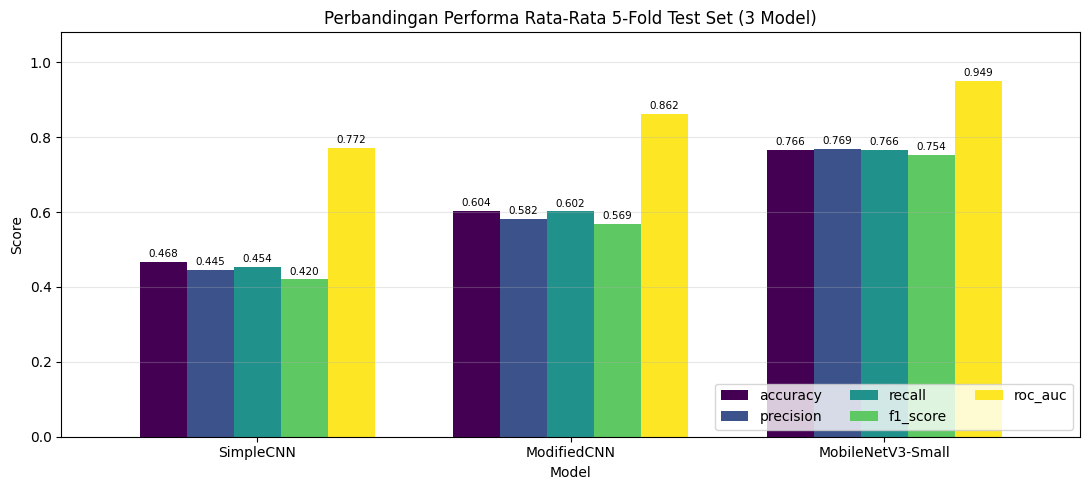

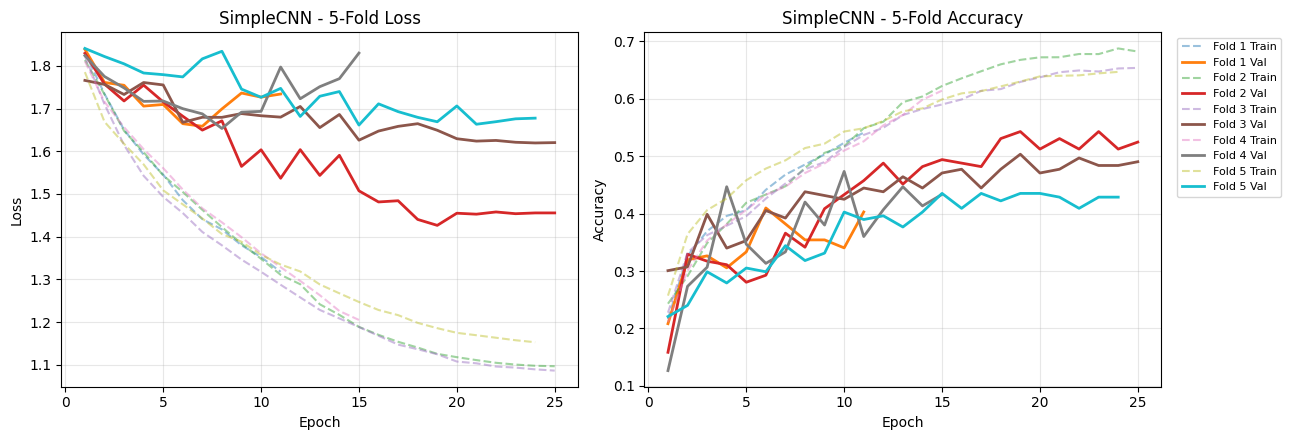

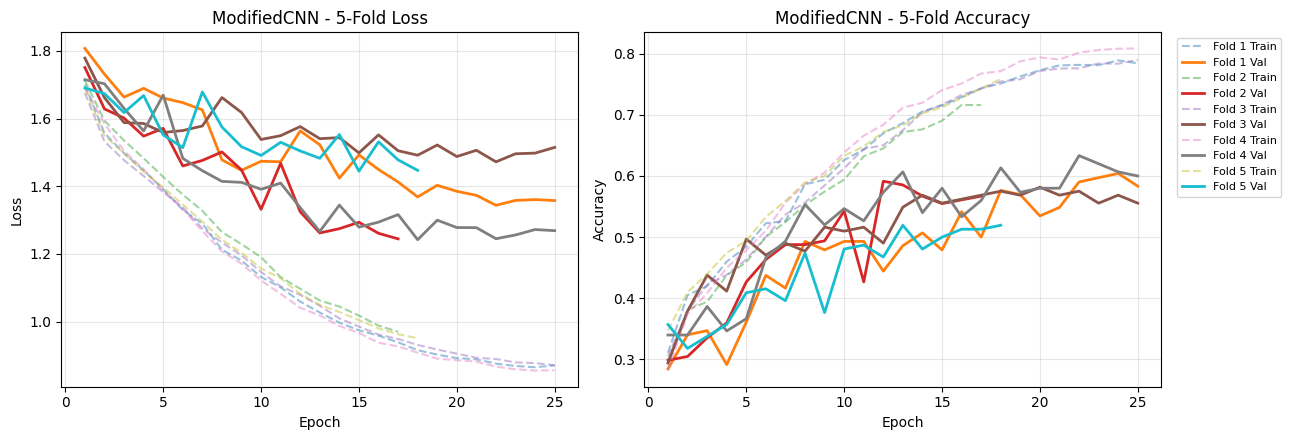

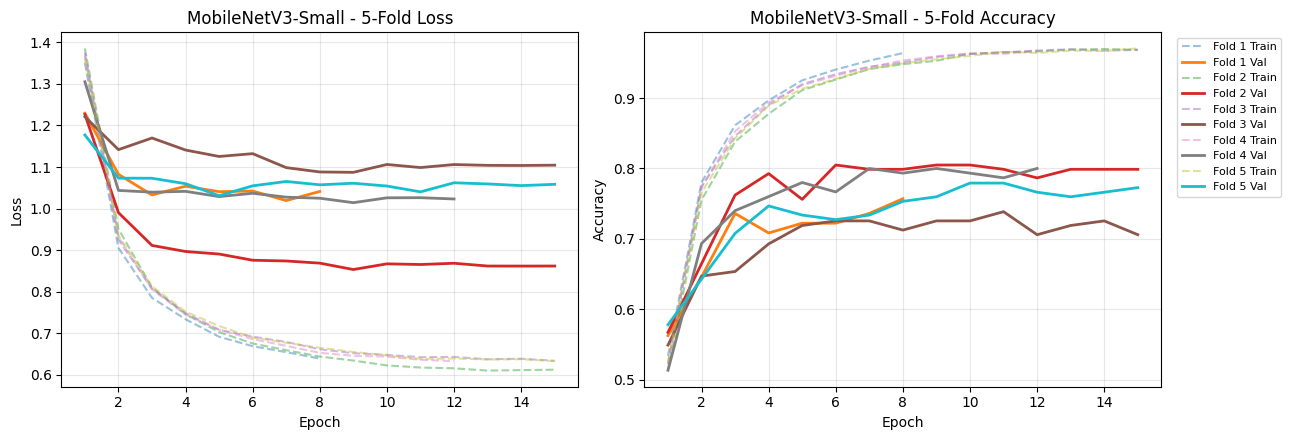

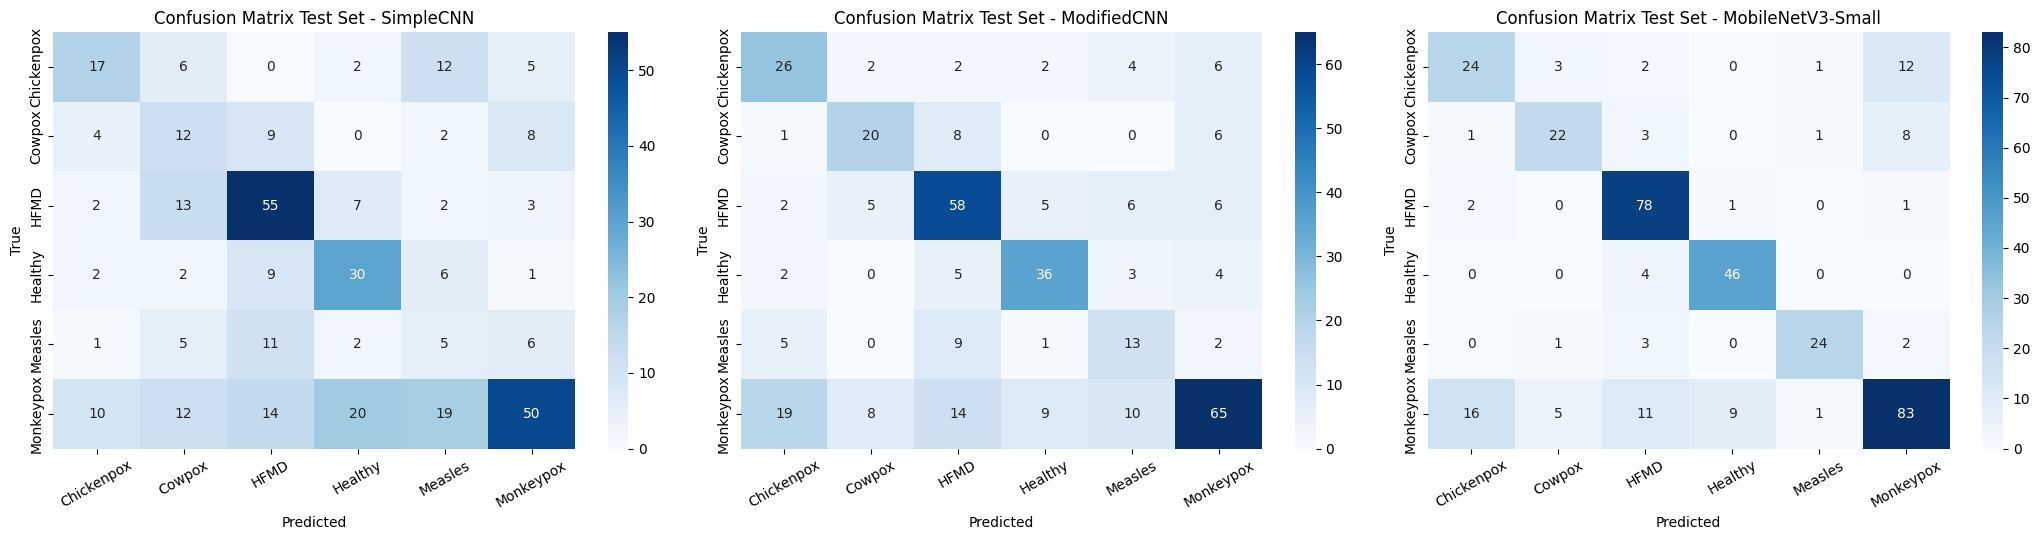

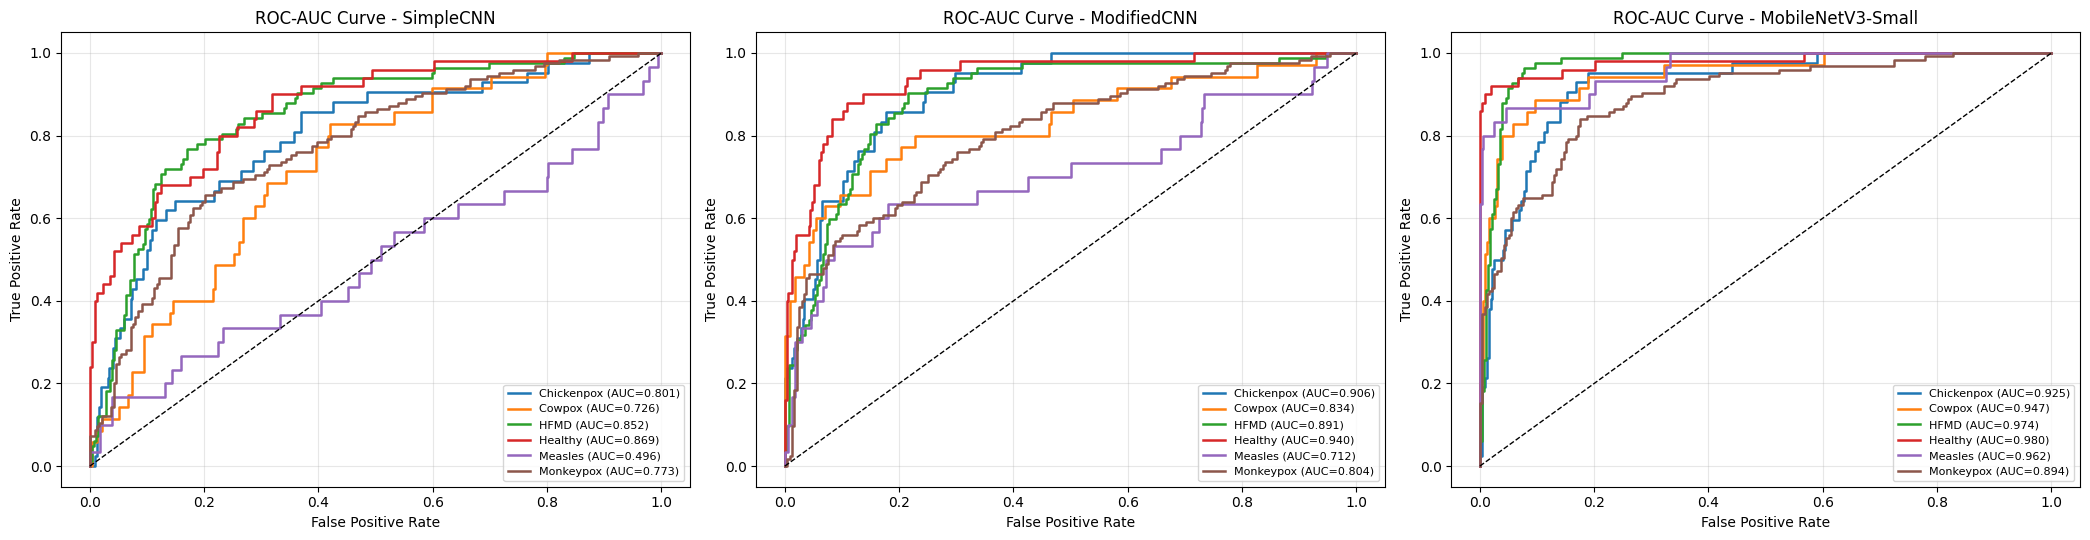

In [13]:
# 1. Grafik Perbandingan Rata-Rata Metrik Test Set (3 Model)
df_test_comp = df_comparison[df_comparison['Split'] == 'Test'].set_index('Model').loc[['SimpleCNN', 'ModifiedCNN', 'MobileNetV3-Small']]
ax = df_test_comp.plot(kind='bar', figsize=(11, 5), width=0.75, colormap='viridis')
plt.title('Perbandingan Performa Rata-Rata 5-Fold Test Set (3 Model)')
plt.ylabel('Score')
plt.ylim(0, 1.08)
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.legend(loc='lower right', ncol=3)
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=7.5, padding=2)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG['output_dir'], 'comparison_3models_bar.png'), dpi=300)
plt.show()

# 2. Kurva Training & Validation (Loss & Accuracy)
for m_name, hists in all_histories.items():
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for f_i, h in enumerate(hists, 1):
        ep_range = range(1, len(h['train_loss']) + 1)  # [UBAH] tiap fold bisa beda panjang (early stopping)
        axes[0].plot(ep_range, h['train_loss'], '--', alpha=0.45, label=f'Fold {f_i} Train')
        axes[0].plot(ep_range, h['val_loss'], lw=2, label=f'Fold {f_i} Val')
        axes[1].plot(ep_range, h['train_acc'], '--', alpha=0.45, label=f'Fold {f_i} Train')
        axes[1].plot(ep_range, h['val_acc'], lw=2, label=f'Fold {f_i} Val')
    axes[0].set_title(f'{m_name} - 5-Fold Loss')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].grid(True, alpha=0.3)
    axes[1].set_title(f'{m_name} - 5-Fold Accuracy')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy'); axes[1].grid(True, alpha=0.3)
    axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(CONFIG['output_dir'], f'training_curves_{m_name}.png'), dpi=300, bbox_inches='tight')
    plt.show()

# 3. Confusion Matrix Akumulasi Test Set
fig, axes = plt.subplots(1, len(all_preds_dict), figsize=(7 * len(all_preds_dict), 5.5))
if len(all_preds_dict) == 1:
    axes = [axes]
for ax_i, (m_name, (yt, yp, _)) in enumerate(all_preds_dict.items()):
    cm = confusion_matrix(yt, yp)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=TARGET_CLASSES, yticklabels=TARGET_CLASSES, ax=axes[ax_i])
    axes[ax_i].set_title(f'Confusion Matrix Test Set - {m_name}')
    axes[ax_i].set_xlabel('Predicted'); axes[ax_i].set_ylabel('True')
    axes[ax_i].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG['output_dir'], 'confusion_matrix_custom_models.png'), dpi=300)
plt.show()

# 4. Multi-Class ROC-AUC Curve
fig, axes = plt.subplots(1, len(all_preds_dict), figsize=(7 * len(all_preds_dict), 5.5))
if len(all_preds_dict) == 1:
    axes = [axes]
for ax_i, (m_name, (yt, _, yprob)) in enumerate(all_preds_dict.items()):
    yt_bin = label_binarize(yt, classes=list(range(len(TARGET_CLASSES))))
    for c_idx in range(len(TARGET_CLASSES)):
        fpr, tpr, _ = roc_curve(yt_bin[:, c_idx], yprob[:, c_idx])
        axes[ax_i].plot(fpr, tpr, lw=1.8, label=f'{TARGET_CLASSES[c_idx]} (AUC={auc(fpr, tpr):.3f})')
    axes[ax_i].plot([0, 1], [0, 1], 'k--', lw=1)
    axes[ax_i].set_title(f'ROC-AUC Curve - {m_name}')
    axes[ax_i].set_xlabel('False Positive Rate'); axes[ax_i].set_ylabel('True Positive Rate')
    axes[ax_i].legend(loc='lower right', fontsize=8); axes[ax_i].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG['output_dir'], 'roc_auc_custom_models.png'), dpi=300)
plt.show()

---
## Tahap 8: Eksplorasi Metode Pre-processing
Untuk memenuhi eksplorasi *pre-processing*, model `MobileNetV3-Small` (model terbaik dan tercepat dilatih) dilatih ulang dengan **3 skema pre-processing** menggunakan konfigurasi yang identik (5-Fold, epoch, LR, augmentasi, *class weight* sama). Satu-satunya yang berbeda adalah pre-processing:

1. **Tanpa Pre-processing**: hanya *resize* `224 × 224` (baseline).
2. **CLAHE**: peningkatan kontras lokal pada kanal L (LAB). Hasilnya diambil dari Tahap 6 agar tidak melatih ulang.
3. **Shades of Gray**: normalisasi warna/pencahayaan (*color constancy*).

Dengan begitu, selisih performa dapat dikaitkan langsung dengan metode pre-processing.


[MobileNetV3-Small | none] FOLD 1/5
Class weights: {'Chickenpox': np.float64(1.79), 'Cowpox': np.float64(1.83), 'HFMD': np.float64(0.77), 'Healthy': np.float64(1.08), 'Measles': np.float64(2.42), 'Monkeypox': np.float64(0.44)}
Ep [01/15] | TrLoss: 1.3563 TrAcc: 0.5299 | ValAcc: 0.5486 ValF1: 0.5549
Ep [02/15] | TrLoss: 0.9028 TrAcc: 0.7852 | ValAcc: 0.6458 ValF1: 0.6566
Ep [03/15] | TrLoss: 0.7859 TrAcc: 0.8580 | ValAcc: 0.6806 ValF1: 0.6922
Ep [04/15] | TrLoss: 0.7373 TrAcc: 0.8982 | ValAcc: 0.6944 ValF1: 0.7036
Ep [05/15] | TrLoss: 0.6920 TrAcc: 0.9273 | ValAcc: 0.7153 ValF1: 0.7119
Ep [06/15] | TrLoss: 0.6717 TrAcc: 0.9383 | ValAcc: 0.7222 ValF1: 0.7145
Ep [07/15] | TrLoss: 0.6580 TrAcc: 0.9506 | ValAcc: 0.7083 ValF1: 0.7070
Ep [08/15] | TrLoss: 0.6438 TrAcc: 0.9595 | ValAcc: 0.7292 ValF1: 0.7259
Ep [09/15] | TrLoss: 0.6379 TrAcc: 0.9647 | ValAcc: 0.7153 ValF1: 0.6924
Ep [10/15] | TrLoss: 0.6316 TrAcc: 0.9672 | ValAcc: 0.7014 ValF1: 0.6880
Ep [11/15] | TrLoss: 0.6279 TrAcc: 0.9678 

,Preprocessing,accuracy,precision,recall,f1_score,roc_auc
0,Tanpa Pre-processing,0.7873 ± 0.0534,0.7995 ± 0.0634,0.7649 ± 0.0513,0.7678 ± 0.0518,0.9518 ± 0.0200
1,CLAHE,0.7660 ± 0.0598,0.7692 ± 0.0671,0.7664 ± 0.0353,0.7535 ± 0.0502,0.9495 ± 0.0185
2,Shades of Gray,0.7724 ± 0.0680,0.7545 ± 0.0901,0.7725 ± 0.0646,0.7533 ± 0.0779,0.9462 ± 0.0216


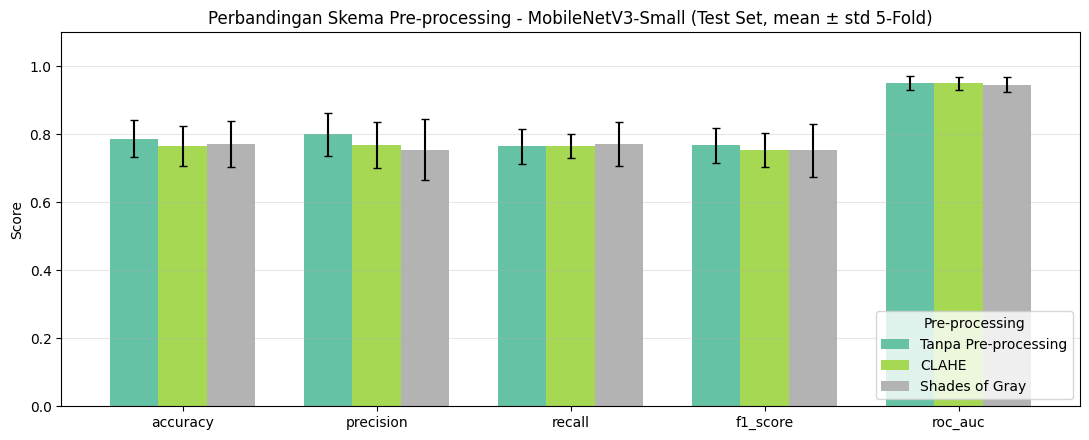

In [14]:
METRICS = ['accuracy', 'precision', 'recall', 'f1_score', 'roc_auc']

def mean_std_table(df, group_cols):
    # Format "mean ± std" antar fold untuk tiap metrik
    g = df.groupby(group_cols)[METRICS]
    mean, std = g.mean(), g.std()
    out = mean.copy().astype(str)
    for col in METRICS:
        out[col] = mean[col].map('{:.4f}'.format) + ' ± ' + std[col].map('{:.4f}'.format)
    return out.reset_index()

if CONFIG['run_preproc_ablation'] and CONFIG['run_mobilenet']:
    abl_model = CONFIG['ablation_model']
    abl_dfs = []
    for method in ['none', 'clahe', 'sog']:
        if method == 'clahe':
            # Hasil CLAHE sudah ada dari Tahap 6 (konfigurasi identik) -> tidak perlu dilatih ulang
            df_t = df_folds_all[(df_folds_all['Model'] == abl_model) & (df_folds_all['Split'] == 'Test')].copy()
        else:
            _, df_t, _, _ = run_5fold_experiment(abl_model, dataset_root=PREPROC_ROOTS[method], tag=method)
        df_t['Preprocessing'] = PREPROC_LABELS[method]
        abl_dfs.append(df_t)

    df_ablation = pd.concat(abl_dfs, ignore_index=True)
    df_ablation.to_csv(os.path.join(CONFIG['output_dir'], 'preprocessing_ablation_per_fold.csv'), index=False)

    df_ablation_ms = mean_std_table(df_ablation, ['Preprocessing'])
    order = [PREPROC_LABELS[m] for m in ['none', 'clahe', 'sog']]
    df_ablation_ms = df_ablation_ms.set_index('Preprocessing').loc[order].reset_index()
    df_ablation_ms.to_csv(os.path.join(CONFIG['output_dir'], 'preprocessing_ablation_mean_std.csv'), index=False)
    print(f'=== EKSPLORASI PRE-PROCESSING ({abl_model}, Test Set, mean ± std 5-Fold) ===')
    display(df_ablation_ms)

    # Grafik batang dengan error bar (std antar fold)
    g = df_ablation.groupby('Preprocessing')[METRICS]
    mean_df, std_df = g.mean().loc[order], g.std().loc[order]
    ax = mean_df.T.plot(kind='bar', yerr=std_df.T, capsize=3, figsize=(11, 4.5), width=0.75, colormap='Set2')
    plt.title(f'Perbandingan Skema Pre-processing - {abl_model} (Test Set, mean ± std 5-Fold)')
    plt.ylabel('Score'); plt.ylim(0, 1.1); plt.xticks(rotation=0); plt.grid(axis='y', alpha=0.3)
    plt.legend(title='Pre-processing', loc='lower right')
    plt.tight_layout()
    plt.savefig(os.path.join(CONFIG['output_dir'], 'preprocessing_ablation.png'), dpi=300)
    plt.show()
else:
    print('Eksplorasi pre-processing dilewati (run_preproc_ablation / run_mobilenet = False).')